# 1. Setup and checks
Quick tests of the generators and estimators.

## Ground Truth Generation

In [1]:
%pip install networkx graphviz numpy pgmpy torch matplotlib ipywidgets nbformat

Note: you may need to restart the kernel to use updated packages.


In [2]:
%load_ext autoreload
%autoreload 2

import os
import logging

import graphviz
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from ndbn.generation import gen_dag_indegree, gen_dag_max_indegree, gen_CPTs
from ndbn.mle import fit_mle, fit_dirichlet
from ndbn.models import DEVICE, nn_probs
from ndbn.training import split_train_val, fit_nn
from ndbn.evaluation import kl_mle, kl_nn, mle_param_stats

os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"
try:
    graphviz.version()
    HAS_GRAPHVIZ = True
except graphviz.ExecutableNotFound:
    HAS_GRAPHVIZ = False   # everything still runs; the DAGs are just not drawn
logging.getLogger("pgmpy").setLevel(logging.ERROR)

print(DEVICE)
print(torch.__version__)        # e.g. 2.8.0+cpu  vs  2.8.0+cu126
print(torch.version.cuda)       # None  => CPU-only build
print(torch.cuda.device_count())

cpu
2.14.0+cu130
13.0
0


In [3]:
from IPython.display import HTML, display
display(HTML("""<style>
.cell-output-ipywidget-background { background-color: transparent !important; }
:root {
  --jp-widgets-color: var(--vscode-editor-foreground);
  --jp-widgets-font-size: var(--vscode-editor-font-size);
}
</style>"""))

### DAG generation

#### Test

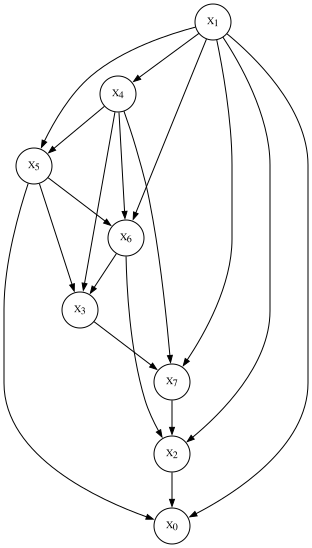

In [4]:
N_NODES = 8
CARDINALITY = 2
ALPHA = 1.0

MAX_IN_DEGREE = 3
MAX_DENSITY = 0.8

dag = gen_dag_indegree(
    n=N_NODES,
    k=MAX_IN_DEGREE,
    seed=123
)

dot = graphviz.Digraph(
    graph_attr={"rankdir": "TB"},
    node_attr={"width": "0.5", "height": "0.5", "fontsize": "10"},
    edge_attr={"arrowsize": "0.7"},
)

for u, v in dag.edges:
    dot.edge(u, v)

for i in range(N_NODES):
    node_id = f"X_{i}"
    dot.node(node_id, label=f"<X<SUB>{i}</SUB>>")

dot if HAS_GRAPHVIZ else print("Graphviz is not installed: DAG not drawn")

### Ground-truth CPTs

#### Test

In [5]:
ground_truth = gen_CPTs(G=dag, card=CARDINALITY, alpha=ALPHA, seed=456)

for cpd in ground_truth.get_cpds():
    print(f"{cpd} \n")

+--------+----------+
| X_1(0) | 0.538859 |
+--------+----------+
| X_1(1) | 0.461141 |
+--------+----------+ 

+--------+---------------------+----------------------+
| X_1    | X_1(0)              | X_1(1)               |
+--------+---------------------+----------------------+
| X_4(0) | 0.32406706937795593 | 0.981314983195667    |
+--------+---------------------+----------------------+
| X_4(1) | 0.6759329306220442  | 0.018685016804333033 |
+--------+---------------------+----------------------+ 

+--------+---------------------+-----+---------------------+
| X_1    | X_1(0)              | ... | X_1(1)              |
+--------+---------------------+-----+---------------------+
| X_4    | X_4(0)              | ... | X_4(1)              |
+--------+---------------------+-----+---------------------+
| X_5(0) | 0.06863164792155352 | ... | 0.5398787090259637  |
+--------+---------------------+-----+---------------------+
| X_5(1) | 0.9313683520784465  | ... | 0.46012129097403637 |
+-----

### Evaluation

### MLE and Dirichlet

#### Test

In [6]:
N, CARD, ALPHA = 2000, 2, 1.0

G = gen_dag_indegree(n=8, k=3, seed=123)
n = G.number_of_nodes()

print(f"Max in-degree = {3}")
print(f"\nDensity: {G.number_of_edges() / (n*(n-1)/2):.3f}")
print("In-degrees:", dict(sorted(G.in_degree(), key=lambda kv: kv[0])))

ground_truth = gen_CPTs(G=G, card=CARDINALITY, alpha=ALPHA, seed=456)

# sample
data = ground_truth.simulate(n_samples=N, seed=3, show_progress=False)
test_data = ground_truth.simulate(n_samples=N, seed=4, show_progress=False)
print(f"\nSampled {len(data)} rows")

# parameter estimation
mle_model = fit_mle(G, data, CARD)

kl, se = kl_mle(ground_truth, mle_model, test_data)
print(f"KL = {kl:>10.4f}")

Max in-degree = 3

Density: 0.643
In-degrees: {'X_0': 3, 'X_1': 0, 'X_2': 3, 'X_3': 3, 'X_4': 1, 'X_5': 2, 'X_6': 3, 'X_7': 3}


/home/kaylin/Neural-Discrete-Bayesian-Network/.venv/lib/python3.14/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (



Sampled 2000 rows
KL =     0.0149


## Neural CPDs

#### Test

In [7]:
# ── Smoke test: NN CPDs run end to end ───────────────────────────────────────
G = gen_dag_indegree(n=5, k=2, seed=0)
true_model = gen_CPTs(G, CARD, alpha=1.0, seed=1)

data = true_model.simulate(n_samples=1000, seed=2, show_progress=False)
test_data = true_model.simulate(n_samples=2000, seed=3, show_progress=False)
train_df, val_df = split_train_val(data, val_frac=0.2, seed=0)

mle = fit_mle(G, data, CARD)   # MLE gets train + val, like the experiments
nn_model = fit_nn(G, train_df, CARD, val_data=val_df, n_epochs=100, verbose=True)

kl_m, _ = kl_mle(true_model, mle, test_data)
kl_n, _ = kl_nn(true_model, nn_model, test_data, CARD)

# probabilities are valid
q = nn_probs(nn_model["X_0"], test_data, CARD)
assert q.shape == (len(test_data), CARD)
assert np.allclose(q.sum(axis=1), 1.0)

print(f"KL  MLE {kl_m:.4f}   NN {kl_n:.4f}")
print(f"params  MLE {mle_param_stats(mle)['stored_params']}"
      f"   NN {nn_model.param_stats()['stored_params']}")


/home/kaylin/Neural-Discrete-Bayesian-Network/ndbn/models.py:66: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  idx = torch.as_tensor(data[parents].to_numpy(np.int64), device=DEVICE)


Node X_2 early stopped at epoch 35. Best val loss=0.4815


Node X_3 early stopped at epoch 45. Best val loss=0.4700


Node X_4 early stopped at epoch 49. Best val loss=0.5113
Epoch 50, val 0.3884


Epoch 100, val 0.3882
KL  MLE 0.0199   NN 0.0101
params  MLE 30   NN 970
